## Introduction

Instead of using the pystac dataset of Planetary computer, we use Google Cloud where a version of the .zar dataset is stored.

We also use the the cartopy dataset. This dataset is particularly useful when we want to experiment

The references on which this tutorial is based are below in this notebook.

In [1]:
!pip install zarr gcsfs xarray cartopy matplotlib --quiet

In [2]:
# Run once if needed (uncomment):
#!pip install zarr gcsfs xarray cartopy matplotlib

import time, warnings
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

import cartopy.crs as ccrs
import cartopy.feature as cfeature

warnings.filterwarnings("ignore")

# plt.rcParams["font.family"] = "sans-serif"
# plt.rcParams["font.sans-serif"] = ["Avenir Next", "Helvetica Neue", "Arial", "DejaVu Sans"]
# BG, INK, MUT = "#ffffff", "#1d2230", "#6b7280"

In [5]:
URL  = "gs://gcp-public-data-arco-era5/ar/full_37-1h-0p25deg-chunk-1.zarr-v3"


In [6]:
%time
ds = xr.open_zarr(URL, storage_options={"token": "anon"}, chunks=None)   # chunks=None: skip the dask graph, read the slice directly

ds

CPU times: user 3 µs, sys: 0 ns, total: 3 µs
Wall time: 6.68 µs


<xarray.Dataset> Size: 4PB
Dimensions:                                                          (
                                                                      time: 1323648,
                                                                      latitude: 721,
                                                                      longitude: 1440,
                                                                      level: 37)
Coordinates:
  * time                                                             (time) datetime64[ns] 11MB ...
  * latitude                                                         (latitude) float32 3kB ...
  * longitude                                                        (longitude) float32 6kB ...
  * level                                                            (level) int64 296B ...
Data variables: (12/273)
    100m_u_component_of_wind                                         (time, latitude, longitude) float32 5TB ...
    100m_v_component_of_wind                                         (time, latitude, longitude) float32 5TB ...
    10m_u_component_of_neutral_wind                                  (time, latitude, longitude) float32 5TB ...
    10m_u_component_of_wind                                          (time, latitude, longitude) float32 5TB ...
    10m_v_component_of_neutral_wind                                  (time, latitude, longitude) float32 5TB ...
    10m_v_component_of_wind                                          (time, latitude, longitude) float32 5TB ...
    ...                                                               ...
    wave_spectral_directional_width_for_swell                        (time, latitude, longitude) float32 5TB ...
    wave_spectral_directional_width_for_wind_waves                   (time, latitude, longitude) float32 5TB ...
    wave_spectral_kurtosis                                           (time, latitude, longitude) float32 5TB ...
    wave_spectral_peakedness                                         (time, latitude, longitude) float32 5TB ...
    wave_spectral_skewness                                           (time, latitude, longitude) float32 5TB ...
    zero_degree_level                                                (time, latitude, longitude) float32 5TB ...
Attributes:
    last_updated:           2026-11-05 03:38:36.598980+00:00
    valid_time_start:       1940-01-01
    valid_time_stop:        2026-06-30
    valid_time_stop_era5t:  2026-10-30

In [7]:
print(f'size: {ds.nbytes / (1024 ** 4)} TB')

size: 3344.695211229595 TB


In [ ]:
## list(ds.data_vars) # To show all the variables

We notice hourly data and this from 1900 and this for 273 variables! Notice that the longitude goes from 0 to 360. Sometimes we see that and sometimes not. You need to check. In order to fix that, you need to do the following fix:

In [8]:
ds = ds.assign_coords(longitude=(((ds.longitude + 180) % 360) - 180)).sortby("longitude")

We see the changes:

In [9]:
ds

<xarray.Dataset> Size: 4PB
Dimensions:                                                          (
                                                                      time: 1323648,
                                                                      latitude: 721,
                                                                      longitude: 1440,
                                                                      level: 37)
Coordinates:
  * time                                                             (time) datetime64[ns] 11MB ...
  * latitude                                                         (latitude) float32 3kB ...
  * longitude                                                        (longitude) float32 6kB ...
  * level                                                            (level) int64 296B ...
Data variables: (12/273)
    100m_u_component_of_wind                                         (time, latitude, longitude) float32 5TB ...
    100m_v_component_of_wind                                         (time, latitude, longitude) float32 5TB ...
    10m_u_component_of_neutral_wind                                  (time, latitude, longitude) float32 5TB ...
    10m_u_component_of_wind                                          (time, latitude, longitude) float32 5TB ...
    10m_v_component_of_neutral_wind                                  (time, latitude, longitude) float32 5TB ...
    10m_v_component_of_wind                                          (time, latitude, longitude) float32 5TB ...
    ...                                                               ...
    wave_spectral_directional_width_for_swell                        (time, latitude, longitude) float32 5TB ...
    wave_spectral_directional_width_for_wind_waves                   (time, latitude, longitude) float32 5TB ...
    wave_spectral_kurtosis                                           (time, latitude, longitude) float32 5TB ...
    wave_spectral_peakedness                                         (time, latitude, longitude) float32 5TB ...
    wave_spectral_skewness                                           (time, latitude, longitude) float32 5TB ...
    zero_degree_level                                                (time, latitude, longitude) float32 5TB ...
Attributes:
    last_updated:           2026-11-05 03:38:36.598980+00:00
    valid_time_start:       1940-01-01
    valid_time_stop:        2026-06-30
    valid_time_stop_era5t:  2026-10-30

We select temperature only. Alternatively, you can also select several variables at the same time. Please see [here](https://github.com/piddy376/30dmc2026/blob/main/day27_new_tool_zarr.ipynb) for an example.

In [11]:
t2m = ds["2m_temperature"]
t2m

<xarray.DataArray '2m_temperature' (time: 1323648, latitude: 721,
                                    longitude: 1440)> Size: 5TB
[1374264299520 values with dtype=float32]
Coordinates:
  * time       (time) datetime64[ns] 11MB 1900-01-01 ... 2050-12-31T23:00:00
  * latitude   (latitude) float32 3kB 90.0 89.75 89.5 ... -89.5 -89.75 -90.0
  * longitude  (longitude) float32 6kB -180.0 -179.8 -179.5 ... 179.5 179.8
Attributes:
    long_name:   2 metre temperature
    short_name:  t2m
    units:       K

In [12]:
t2m = t2m.sel(time = '2025-01-01T02:00:00')
t2m

<xarray.DataArray '2m_temperature' (latitude: 721, longitude: 1440)> Size: 4MB
[1038240 values with dtype=float32]
Coordinates:
  * latitude   (latitude) float32 3kB 90.0 89.75 89.5 ... -89.5 -89.75 -90.0
  * longitude  (longitude) float32 6kB -180.0 -179.8 -179.5 ... 179.5 179.8
    time       datetime64[ns] 8B 2025-01-01T02:00:00
Attributes:
    long_name:   2 metre temperature
    short_name:  t2m
    units:       K

In [13]:
t2m.encoding["chunks"]

(1, 721, 1440)

In [14]:
print(f'{t2m.nbytes / (1024 ** 2):.2f} MB')

3.96 MB


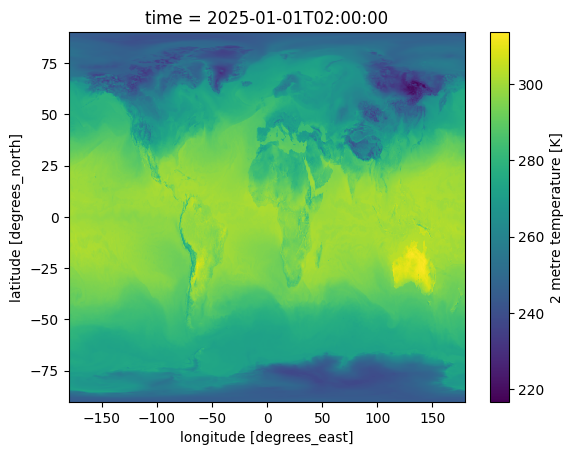

In [15]:
t2m.plot()

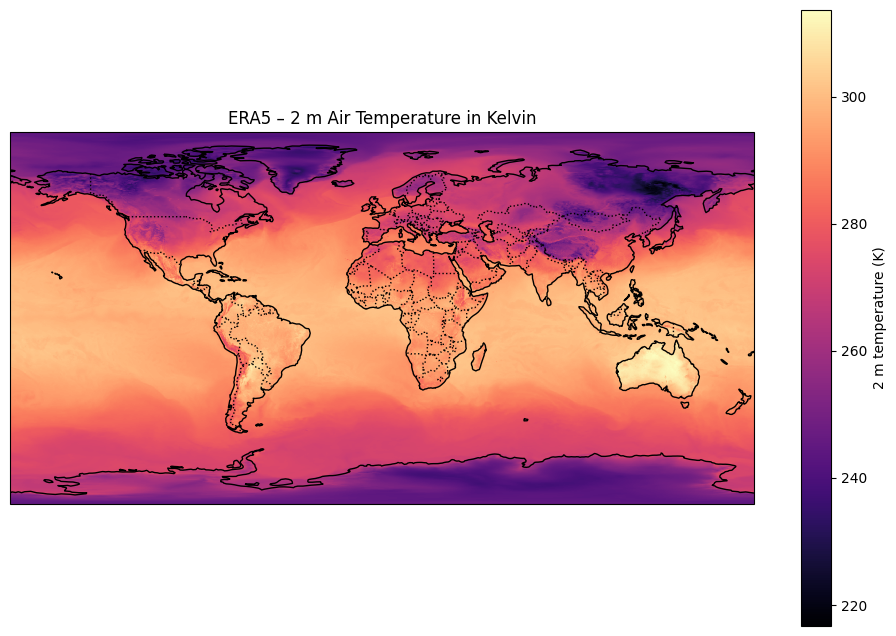

In [18]:
fig, ax = plt.subplots(
    figsize=(12, 8),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

t2m.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="magma",
    cbar_kwargs={"label": "2 m temperature (K)"}
)

ax.coastlines()
ax.add_feature(cfeature.BORDERS, linestyle=":")
ax.add_feature(cfeature.LAND, facecolor="none")

ax.set_title("ERA5 – 2 m Air Temperature in Kelvin")

plt.show()

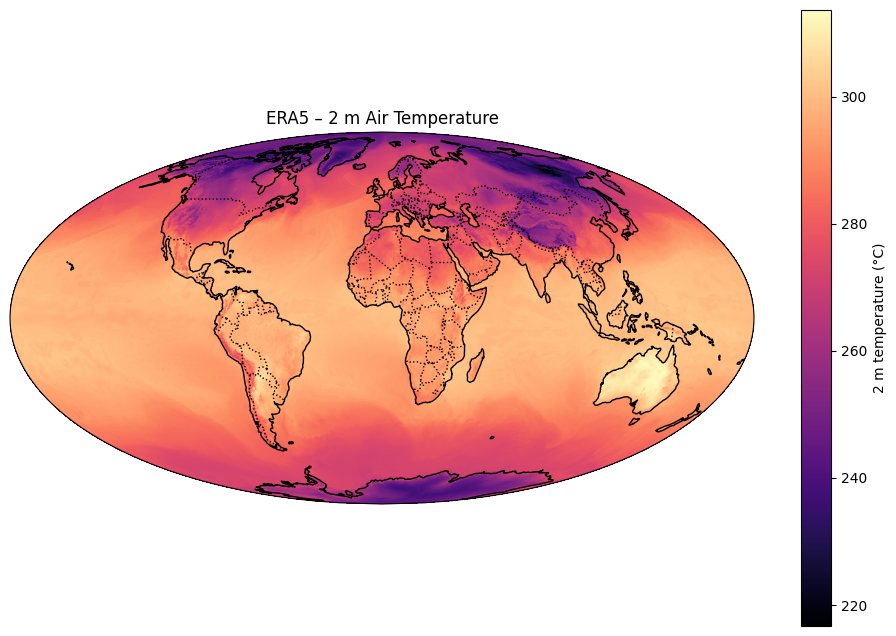

In [19]:
fig, ax = plt.subplots(
    figsize=(12, 8),
    subplot_kw={"projection": ccrs.Mollweide()}
)

t2m.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="magma",
    cbar_kwargs={"label": "2 m temperature (°C)"}
)

ax.coastlines()
ax.add_feature(cfeature.BORDERS, linestyle=":")
ax.add_feature(cfeature.LAND, facecolor="none")

ax.set_global()

ax.set_title("ERA5 – 2 m Air Temperature")

plt.show()

Let's add some more bells and whistles:

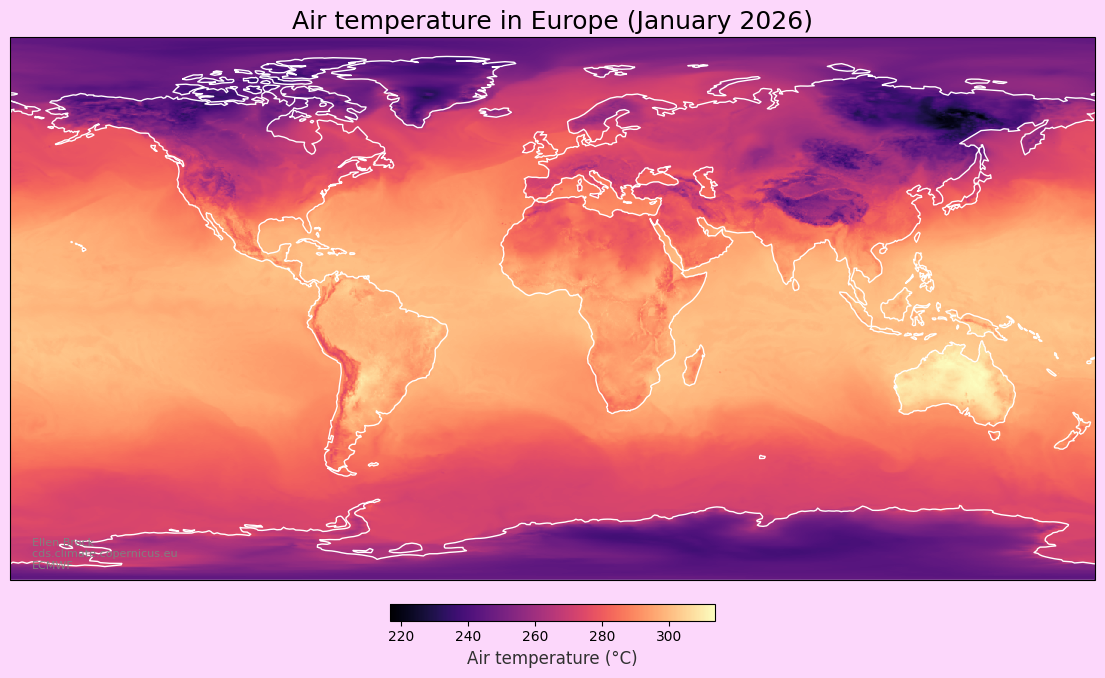

In [ ]:
fig = plt.figure(figsize=(14, 8), facecolor = '#FCD7FB')
ax = plt.subplot(1,1,1, projection=ccrs.PlateCarree())

ax.coastlines(color='white') # Add coastlines
im = plt.pcolormesh(t2m.longitude, t2m.latitude, t2m, cmap='magma')

plt.title("Air temperature in Europe (January 2025)", size = 18)

cbar = plt.colorbar(im,fraction=0.046, pad=0.04, location = 'bottom', shrink = 0.3)
cbar.set_label(
    f"Air temperature (°C)",
    size=12,
    color='#303030'
)
txt = ax.text(0.02, 0.02, "Ellen Brock \ncds.climate.copernicus.eu \nECMWF",
              size=8,
              color='gray',
              transform = ax.transAxes)

plt.savefig(
    "air_temperature_europe_jan_2026.png",
    dpi=300,
    bbox_inches='tight',
    facecolor=fig.get_facecolor()
)

plt.show()

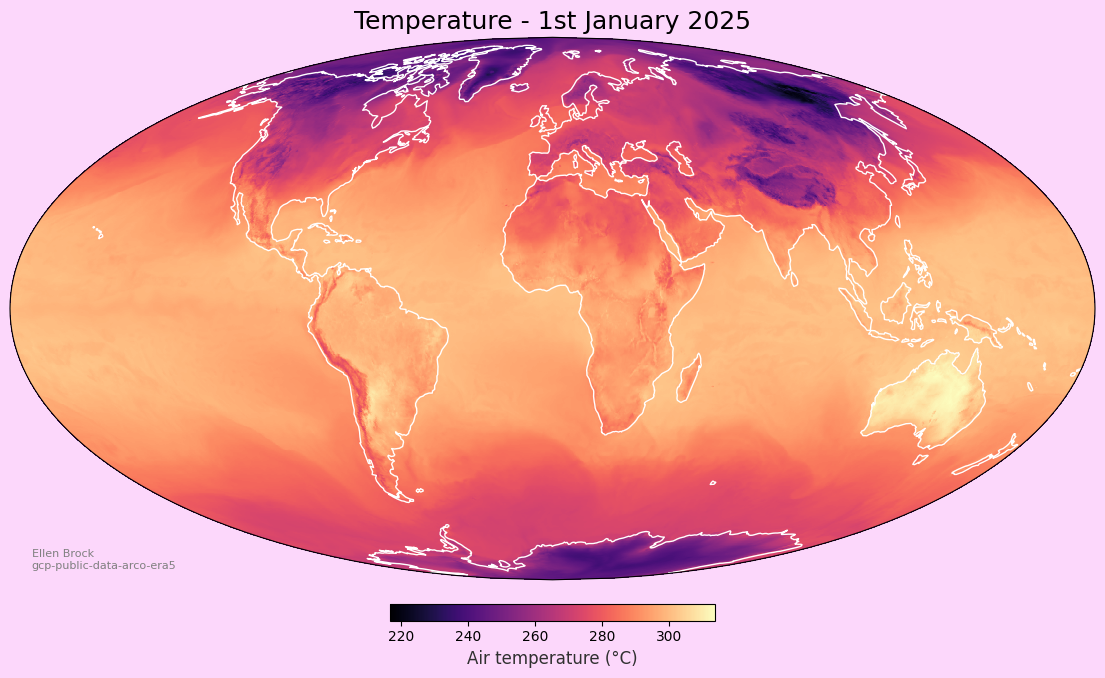

In [32]:
fig = plt.figure(figsize=(14, 8), facecolor='#FCD7FB')

ax = plt.subplot(
    1, 1, 1,
    projection=ccrs.Mollweide()
)

ax.coastlines(color='white')

im = ax.pcolormesh(
    t2m.longitude,
    t2m.latitude,
    t2m,
    cmap='magma',
    transform=ccrs.PlateCarree()
)

ax.set_global()

plt.title("Temperature - 1st January 2025", fontsize=18)

cbar = plt.colorbar(
    im,
    fraction=0.046,
    pad=0.04,
    location='bottom',
    shrink=0.3
)

cbar.set_label(
    "Air temperature (°C)",
    size=12,
    color='#303030'
)

txt = ax.text(
    0.02, 0.02,
    "Ellen Brock\ngcp-public-data-arco-era5",
    size=8,
    color='gray',
    transform=ax.transAxes
)

plt.savefig(
    "air_temperature_europe_jan_2025.png",
    dpi=300,
    bbox_inches='tight',
    facecolor=fig.get_facecolor()
)

plt.show()

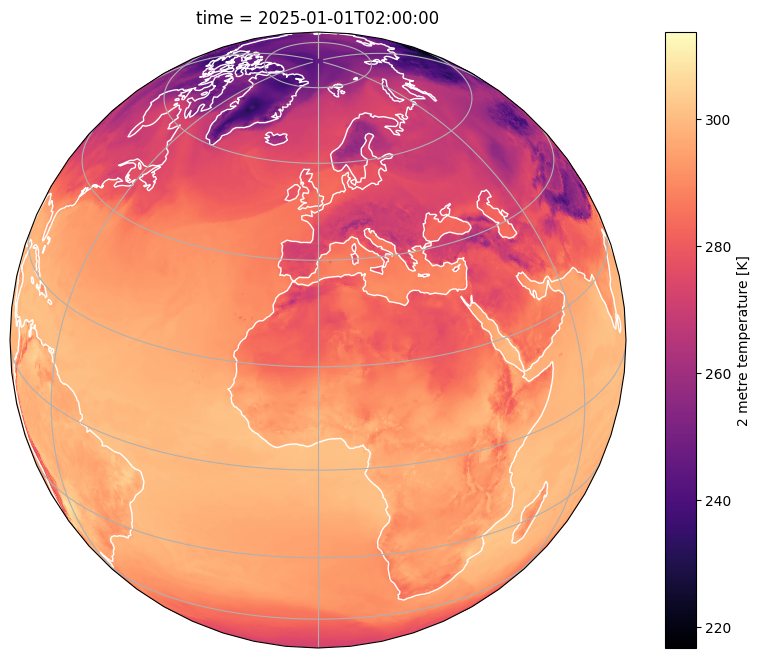

In [20]:
map_projection = ccrs.Orthographic(central_longitude=0, central_latitude=25)

fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': map_projection})

# 3. Add geographic context
ax.coastlines(color = 'white')
ax.gridlines()

# 4. Plot the temperature data
# projection = how the map LOOKS | transform = how the data is DEFINED
im = t2m.plot(
    ax=ax,
    x='longitude',
    y='latitude',
    transform=ccrs.PlateCarree(),  # Coordinates are in degrees lat/lon
    cmap='magma'
)

plt.show()

Using color mesh - Just experimented!

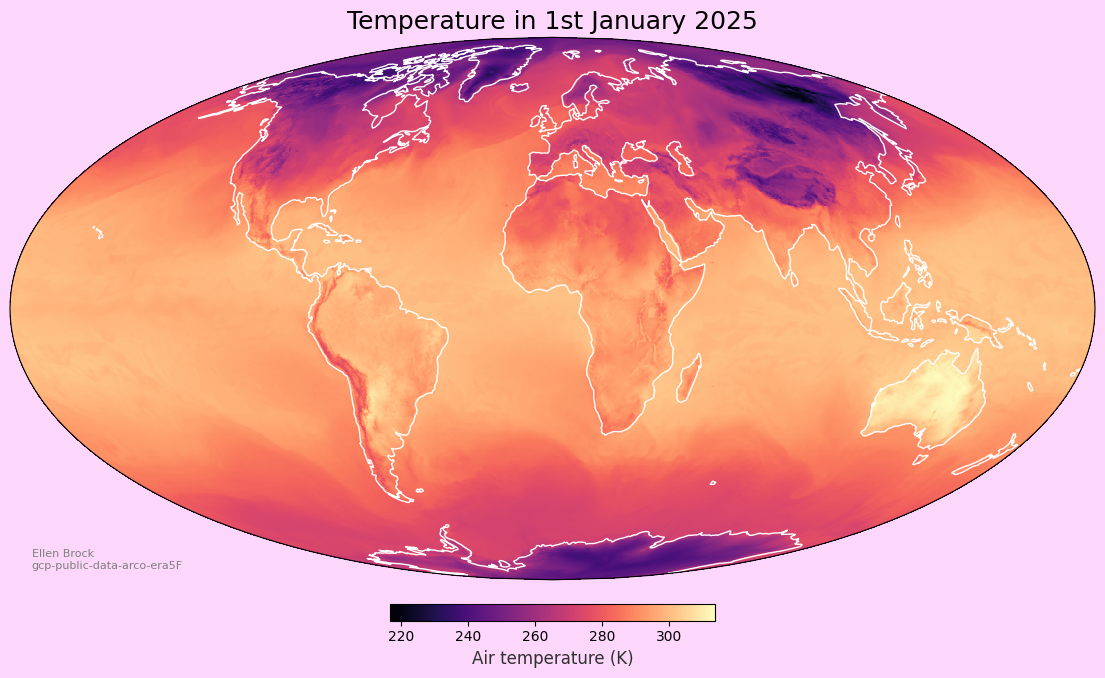

In [28]:
fig = plt.figure(figsize=(14, 8), facecolor='#FCD7FB')

ax = plt.subplot(
    1, 1, 1,
    projection=ccrs.Mollweide()
)

ax.coastlines(color='white')

im = ax.pcolormesh(
    t2m.longitude,
    t2m.latitude,
    t2m,
    cmap='magma',
    transform=ccrs.PlateCarree()
)

ax.set_global()

plt.title("Temperature - 1st January 2025", size=18)

cbar = plt.colorbar(
    im,
    fraction=0.046,
    pad=0.04,
    location='bottom',
    shrink=0.3
)

cbar.set_label(
    "Air temperature (K)",
    size=12,
    color='#303030'
)

txt = ax.text(
    0.02, 0.02,
    "Ellen Brock\ngcp-public-data-arco-era5F",
    size=8,
    color='gray',
    transform=ax.transAxes
)

plt.savefig(
    "temperature_january_2025.png",
    dpi=300,
    bbox_inches='tight',
    facecolor=fig.get_facecolor()
)

plt.show()

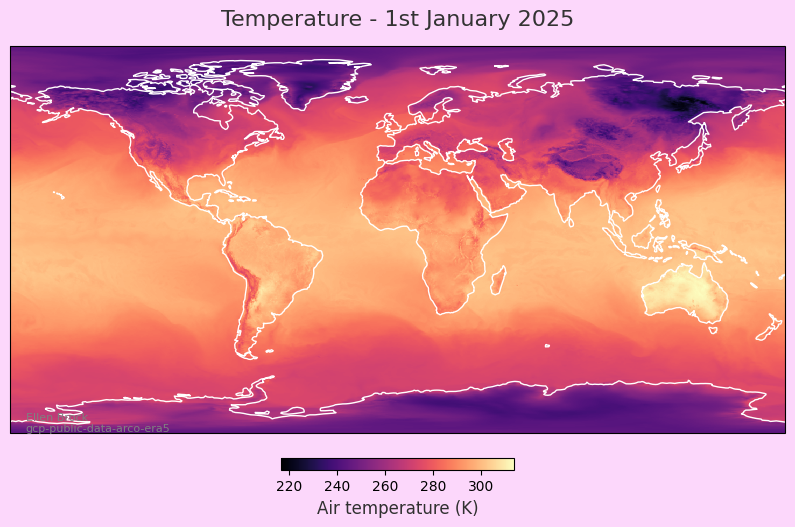

In [37]:
map_projection = ccrs.PlateCarree()

fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': map_projection},
                       facecolor='#FCD7FB')

ax.coastlines(color = 'white')
## ax.gridlines()

im = t2m.plot(
    ax=ax,
    x='longitude',
    y='latitude',
    transform=ccrs.PlateCarree(),  # Coordinates are in degrees lat/lon
    cmap='magma',
    add_colorbar=False
)

cbar = plt.colorbar(
    im,
    fraction=0.046,
    pad=0.04,
    location='bottom',
    shrink=0.3
)

cbar.set_label(
    "Air temperature (K)",
    size=12,
    color='#303030'
)
ax.set_title('Temperature - 1st January 2025', fontsize=16, pad=15, color='#333333')

txt = ax.text(
    0.02, 0.005,
    "Ellen Brock\ngcp-public-data-arco-era5",
    size=8,
    color='gray',
    transform=ax.transAxes
)

plt.show()

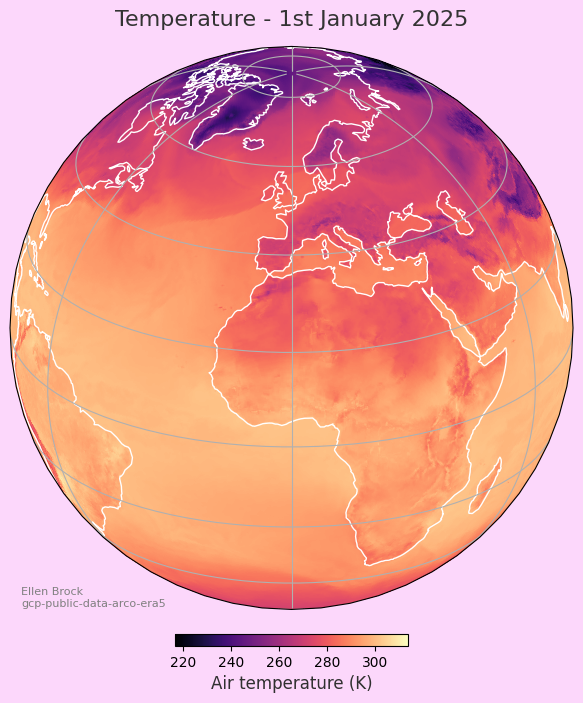

In [38]:
map_projection = ccrs.Orthographic(central_longitude=0, central_latitude=25)

fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': map_projection},
                       facecolor='#FCD7FB')

ax.coastlines(color = 'white')
ax.gridlines()

im = t2m.plot(
    ax=ax,
    x='longitude',
    y='latitude',
    transform=ccrs.PlateCarree(),  # Coordinates are in degrees lat/lon
    cmap='magma',
    add_colorbar=False
)

cbar = plt.colorbar(
    im,
    fraction=0.046,
    pad=0.04,
    location='bottom',
    shrink=0.3
)

cbar.set_label(
    "Air temperature (K)",
    size=12,
    color='#303030'
)
ax.set_title('Temperature - 1st January 2025', fontsize=16, pad=15, color='#333333')

txt = ax.text(
    0.02, 0.005,
    "Ellen Brock\ngcp-public-data-arco-era5",
    size=8,
    color='gray',
    transform=ax.transAxes
)

plt.show()

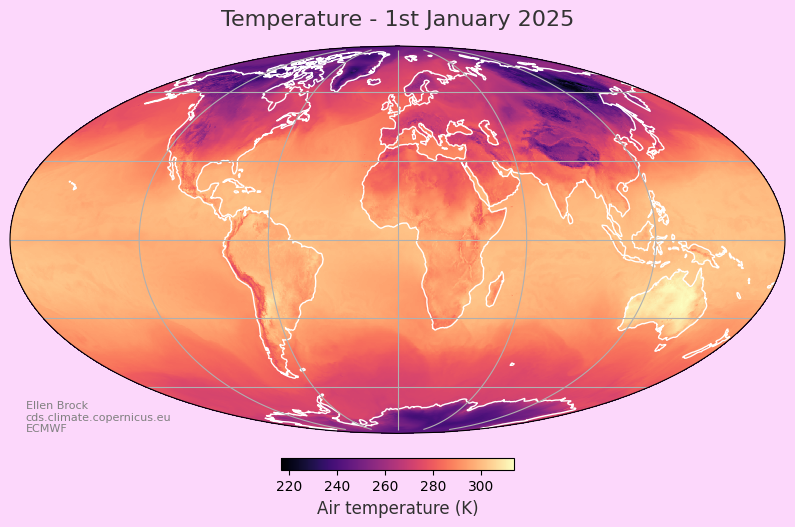

In [39]:
map_projection = ccrs.Mollweide() # projection on the map

fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': map_projection},
                       facecolor='#FCD7FB')

ax.coastlines(color = 'white')
ax.gridlines()

im = t2m.plot(
    ax=ax,
    x='longitude',
    y='latitude',
    transform=ccrs.PlateCarree(),  # Coordinates are in degrees lat/lon
    cmap='magma',
    add_colorbar=False
)

cbar = plt.colorbar(
    im,
    fraction=0.046,
    pad=0.04,
    location='bottom',
    shrink=0.3
)

cbar.set_label(
    "Air temperature (K)",
    size=12,
    color='#303030'
)
ax.set_title('Temperature - 1st January 2025', fontsize=16, pad=15, color='#333333')

txt = ax.text(
    0.02, 0.005,
    "Ellen Brock\ncds.climate.copernicus.eu\nECMWF",
    size=8,
    color='gray',
    transform=ax.transAxes
)

plt.show()

## References

https://docs.xarray.dev/en/stable/user-guide/plotting.html

[Mapping and data visualisation in Python with Ujaval Gandhi www.spatialthoughts.com](https://courses.spatialthoughts.com/python-dataviz.html#plotting-using-cartopy)

[Technical GIS, ERA5 in Python with xarray: mapping the July 2022 UK heatwave](https://www.technicalgis.com/tutorials/era5-python-xarray/)

https://github.com/piddy376/30dmc2026/blob/main/day22_projections.ipynb

https://github.com/piddy376/30dmc2026/blob/main/day27_new_tool_zarr.ipynb